# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Перхун Максим'      # прізвище та ім'я
GROUP        = 'ШІ-34'              # шифр групи, наприклад СШІ-31
NUMBER       = 11                   # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Перхун Максим | ШІ-34 | номер 11


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 11   ·   Перхун Максим   ·   ШІ-34

   Ринок:  Mykolaiv
   Товар:  масло   (у наборі даних: Butter - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Завдання 1. Підготовка ряду
import warnings; warnings.filterwarnings('ignore')
import os
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
mpl.rcParams.update({'font.family': 'DejaVu Sans', 'figure.figsize': (11, 3.8), 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 11, 'axes.labelsize': 10})
C_MAIN, C_ACC, C_GREY = '#2C6E9B', '#C0392B', '#7F8C8D'

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))
GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS')           # повна місячна сітка

raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)].sort_values('date').set_index('date')['ціна'])
assert raw.index.is_unique
s = raw.reindex(GRID); s.index.name = 'date'                           # приводимо до ПОВНОЇ сітки
gaps = s[s.isna()].index

print(f'Місяців у сітці: {len(GRID)}; з виміром: {s.notna().sum()}; без виміру: {len(gaps)}')
print('Пропущений місяць:', [d.strftime('%m.%Y') for d in gaps])
aug17 = pd.Timestamp('2017-08-01')
series_gaps = prices.groupby(['ринок', 'товар'])['date'].apply(lambda d: tuple(sorted(set(GRID) - set(d))))
print(f'Серпня 2017 немає у {series_gaps.apply(lambda g: aug17 in g).sum()} із {len(series_gaps)} рядів набору (ринок × товар)')

Місяців у сітці: 46; з виміром: 45; без виміру: 1
Пропущений місяць: ['08.2017']
Серпня 2017 немає у 700 із 700 рядів набору (ринок × товар)


**Висновок до завдання 1:**
1. У сітці **46 місяців**, виміряно **45**.
2. Пропуск — **серпень 2017**; у моєму ряді він **один**.
3. Серпня 2017 немає в усіх 700 рядах набору, тож це не особливість Миколаєва чи масла, а дірка в самому джерелі (місяць не зібрано або не опубліковано). Чому саме, з набору встановити не можна — це припущення, а не перевірений факт.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску
T = pd.Timestamp('2017-08-01')
methods = {'перенесення останнього (ffill)': s.ffill()[T], 'лінійна інтерполяція': s.interpolate('linear')[T],
           'кубічний сплайн': s.interpolate('cubic')[T]}
jul, sep = s[pd.Timestamp('2017-07-01')], s[pd.Timestamp('2017-09-01')]
tab = pd.DataFrame({'значення, грн': methods})
tab['зміна лип→сер, %'] = (tab['значення, грн'] / jul - 1) * 100
tab['зміна сер→вер, %'] = (sep / tab['значення, грн'] - 1) * 100
print(f'Сусіди пропуску: липень 2017 = {jul:.2f}, вересень 2017 = {sep:.2f}')
print(tab.round(2).to_string())

# Обрана версія: лінійна інтерполяція, округлена до 4 знаків (як у вихідних даних),
# щоб Python і Orange працювали з однаковими числами
y = s.interpolate('linear').round(4); y.name = 'price'
assert y.notna().all() and len(y) == 46

# Приклад із набору, де заповнювати не можна: ряд закінчився
cnt = prices.groupby('ринок')['date'].agg(['max', 'nunique'])
print('\nРинки, що зникають з набору до кінця періоду (останній місяць, кількість спостережень):')
print(cnt[cnt['max'] < '2017-12-01'].to_string())

Сусіди пропуску: липень 2017 = 140.39, вересень 2017 = 145.45
                                значення, грн  зміна лип→сер, %  зміна сер→вер, %
перенесення останнього (ffill)         140.39              0.00              3.61
лінійна інтерполяція                   142.92              1.80              1.77
кубічний сплайн                        143.97              2.55              1.03

Ринки, що зникають з набору до кінця періоду (останній місяць, кількість спостережень):
                     max  nunique
ринок                            
Crimea        2014-03-01        1
m. Sevastopol 2014-04-01        2


**Висновок до завдання 2:**
1. Значення за серпень 2017 (сусіди: 140,39 і 145,45): ffill — **140,39**, лінійна інтерполяція — **142,92**, кубічний сплайн — **143,97**.
2. **Обрано лінійну.** Ряд зростає, тому ffill занижує значення на 2,5 грн і дає «нульову» зміну в серпні та стрибок +3,6 % у вересні. Кубічний сплайн використовує далекі точки й дає вище значення без підстав. Лінійна бере лише двох сусідів з обох боків; вона є й в Orange.
3. **Неприпустимо заповнювати, коли ряд закінчився, а не має «дірку».** У наборі це **Крим** (1 спостереження, 03.2014) і **м. Севастополь** (2): «заповнення» решти місяців вигадало б ціни на ринку, якого в даних більше немає.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

Три найбільші місячні зміни: 03.2015: +11.4%, 11.2016: +11.2%, 12.2015: +7.2%
Ці 3 місяці з 45 дають 32% усього логарифмічного зростання ціни (ціна ×2.45)


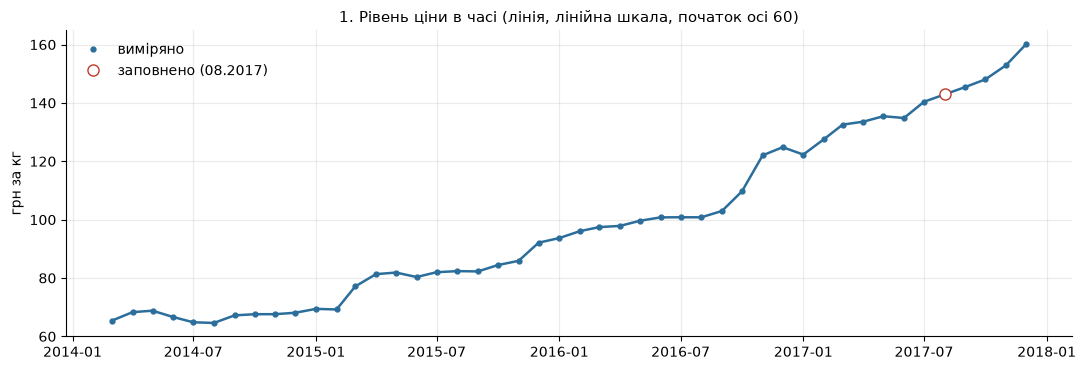

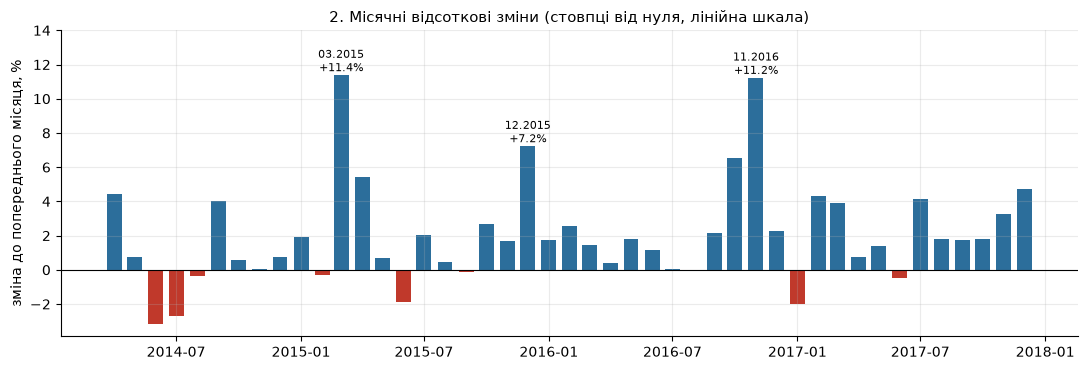

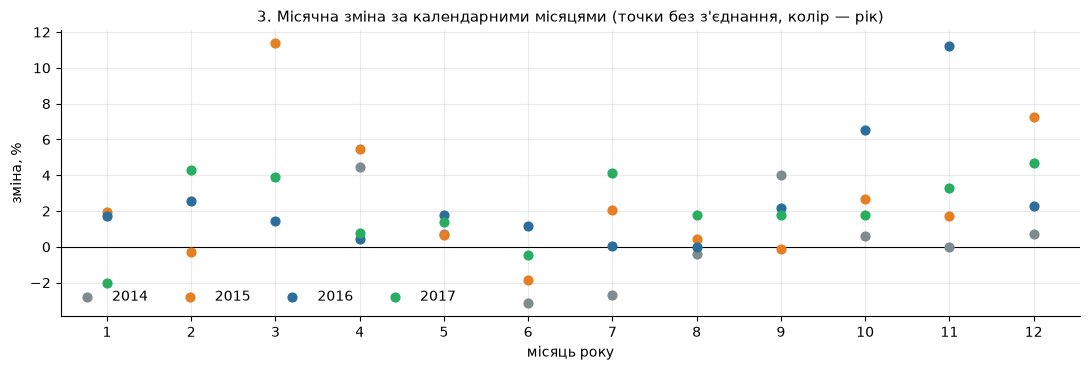

In [5]:
# Завдання 3. Візуальна розвідка
mom = y.pct_change() * 100                                               # місячна зміна, %
top3 = mom.abs().nlargest(3).index
share = np.log(1 + mom[top3] / 100).sum() / np.log(y.iloc[-1] / y.iloc[0])
print('Три найбільші місячні зміни:', ', '.join(f'{d:%m.%Y}: {mom[d]:+.1f}%' for d in top3))
print(f'Ці 3 місяці з 45 дають {share*100:.0f}% усього логарифмічного зростання ціни (ціна ×{y.iloc[-1]/y.iloc[0]:.2f})')

# 1. Рівень ряду: лінія, лінійна шкала
fig, ax = plt.subplots()
ax.plot(y.index, y.values, color=C_MAIN, lw=1.8); ax.plot(s.index, s.values, 'o', ms=3.5, color=C_MAIN, label='виміряно')
ax.plot([T], [y[T]], 'o', mfc='white', mec=C_ACC, ms=8, label='заповнено (08.2017)')
ax.set_ylim(60, None); ax.set_ylabel('грн за кг'); ax.legend(frameon=False)
ax.set_title('1. Рівень ціни в часі (лінія, лінійна шкала, початок осі 60)'); plt.tight_layout(); plt.show()

# 2. Відносні зміни: стовпці від нуля
fig, ax = plt.subplots()
ax.bar(mom.index, mom.values, width=22, color=np.where(mom.values >= 0, C_MAIN, C_ACC))
for d in top3: ax.annotate(f'{d:%m.%Y}\n{mom[d]:+.1f}%', (d, mom[d]), ha='center', va='bottom', fontsize=8)
ax.axhline(0, color='k', lw=.8); ax.set_ylabel('зміна до попереднього місяця, %'); ax.set_ylim(top=14)
ax.set_title('2. Місячні відсоткові зміни (стовпці від нуля, лінійна шкала)'); plt.tight_layout(); plt.show()

# 3. Календарний візерунок: точки за місяцями року, колір — рік
fig, ax = plt.subplots()
d3 = mom.dropna().to_frame('m'); d3['month'] = d3.index.month; d3['year'] = d3.index.year
cols = {2014: '#7F8C8D', 2015: '#E67E22', 2016: '#2C6E9B', 2017: '#27AE60'}
for yr, g in d3.groupby('year'): ax.scatter(g['month'], g['m'], s=40, color=cols[yr], label=str(yr), zorder=3)
ax.axhline(0, color='k', lw=.8); ax.set_xticks(range(1, 13)); ax.set_xlabel('місяць року'); ax.set_ylabel('зміна, %')
ax.set_title('3. Місячна зміна за календарними місяцями (точки без з\'єднання, колір — рік)'); ax.legend(ncol=4, frameon=False)
plt.tight_layout(); plt.show()

**Висновок до завдання 3:**
1. **Графік 1** (лінія, лінійна шкала, початок осі 60): питання — як змінювався *рівень* ціни; лінія, бо час упорядкований і безперервний, нуль не потрібен (порівнюється форма руху). **Графік 2** (стовпці від нуля, % до попереднього місяця): питання — наскільки *швидко й рівномірно* росте ціна; зміна має знак, тому стовпці від нуля, а відсотки прибирають вплив зростаючого рівня. **Графік 3** (точки за календарними місяцями, колір — рік): питання — чи є *календарний візерунок*; точки без з'єднання, бо це окремі спостереження, а не траєкторія.
2. **Несподівана знахідка:** зростання східчасте. Три місяці з 45 — 03.2015 (+11,4 %), 11.2016 (+11,2 %), 12.2015 (+7,2 %) — дають **32 %** усього логарифмічного зростання.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

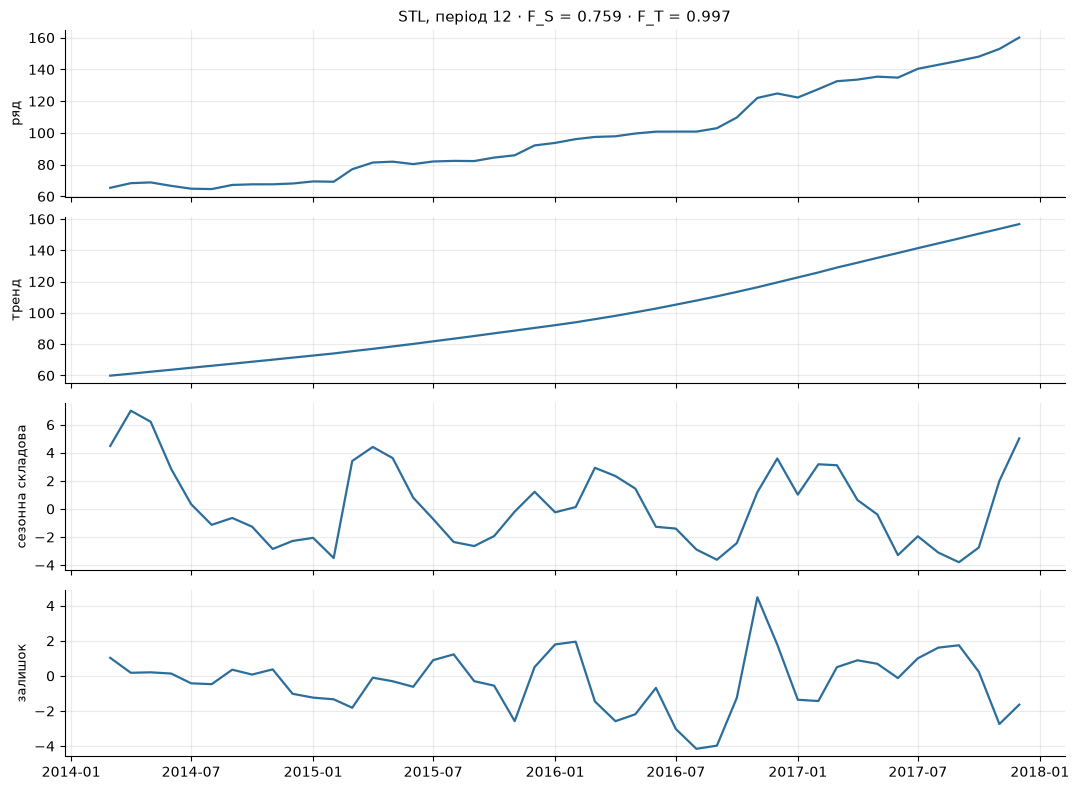

F_S = 0.759   F_T = 0.997   (поріг сезонності 0.3)
Для перемішаних приростів: медіана F_S = 0.63; частка симуляцій з F_S ≥ 0.759: 0.13


In [6]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

def strengths(res):
    R = res.resid
    return (max(0, 1 - R.var() / (res.seasonal + R).var()), max(0, 1 - R.var() / (res.trend + R).var()))   # F_S, F_T

stl = STL(y, period=12).fit()
FS, FT = strengths(stl)
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, d, t in zip(axes, [y, stl.trend, stl.seasonal, stl.resid], ['ряд', 'тренд', 'сезонна складова', 'залишок']):
    ax.plot(d.index, d.values, color=C_MAIN, lw=1.6); ax.set_ylabel(t, fontsize=9)
axes[0].set_title(f'STL, період 12 · F_S = {FS:.3f} · F_T = {FT:.3f}'); plt.tight_layout(); plt.show()
print(f'F_S = {FS:.3f}   F_T = {FT:.3f}   (поріг сезонності 0.3)')

# Контроль: який F_S дає ряд без календарної структури (ті самі прирости в перемішаному порядку)?
rng = np.random.default_rng(42); inc = np.diff(y.values); null = []
for _ in range(300):
    sim = pd.Series(np.r_[y.values[0], y.values[0] + np.cumsum(rng.permutation(inc))], index=y.index)
    null.append(strengths(STL(sim, period=12).fit())[0])
null = np.array(null)
print(f'Для перемішаних приростів: медіана F_S = {np.median(null):.2f}; частка симуляцій з F_S ≥ {FS:.3f}: {(null >= FS).mean():.2f}')

**Висновок до завдання 4:**
- **F_S = 0,759, F_T = 0,997.** Тренд домінує майже повністю.
- **Чи є сезонність:** за пороговим значенням 0,3 — **так, формально є** (0,759 > 0,3).
- **Застереження:** для рядів з тими ж приростами в перемішаному порядку (без календаря) F_S має медіану 0,63, і у 13 % таких рядів він не менший за мій (p ≈ 0,13). Тобто на короткому ряді з сильним трендом поріг 0,3 слабко відрізняє сезон від шуму, а даних лише ≈ 3,8 циклу. Тому сезонність слід вважати **слабкою й непевною**.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

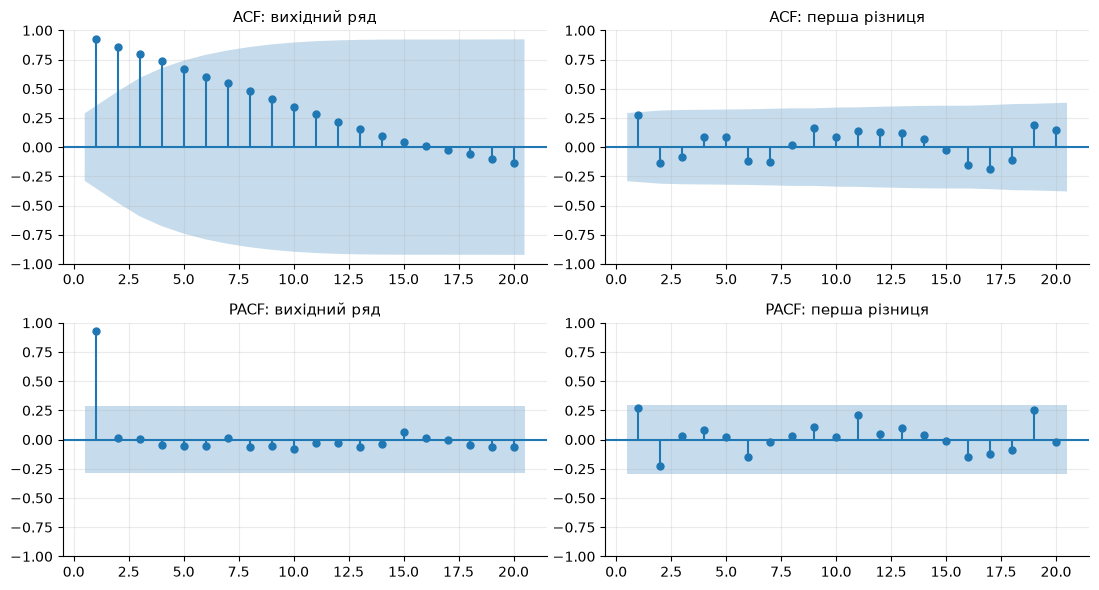

Різниця: межа значущості ±0.292; ACF лаги 1–3: [ 0.273 -0.136 -0.082]; PACF лаги 1–3: [ 0.273 -0.228  0.029]

           ряд  ADF p ADF: стаціонарний?  KPSS p KPSS: стаціонарний?
 вихідний ряд 0.9989                 ні  0.0100                  ні
перша різниця 0.0001                так  0.0197                  ні
(statsmodels обмежує p-значення KPSS діапазоном [0.01; 0.10])

Середній місячний приріст ціни за роками, грн: {2014: 0.3, 2015: 2.0, 2016: 2.73, 2017: 2.94}


C:\Users\s1fle\AppData\Local\Temp\ipykernel_32640\659450419.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  a, k = adfuller(x, autolag='AIC')[1], kpss(x, regression='c', nlags='auto')[1]


In [7]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf

d1 = y.diff().dropna()
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for j, (x, nm) in enumerate([(y, 'вихідний ряд'), (d1, 'перша різниця')]):
    plot_acf(x, lags=20, ax=axes[0, j], zero=False, title=f'ACF: {nm}')
    plot_pacf(x, lags=20, ax=axes[1, j], zero=False, method='ywm', title=f'PACF: {nm}')
plt.tight_layout(); plt.show()
print(f'Різниця: межа значущості ±{1.96/np.sqrt(len(d1)):.3f}; ACF лаги 1–3: {acf(d1, nlags=3)[1:].round(3)}; PACF лаги 1–3: {pacf(d1, nlags=3, method="ywm")[1:].round(3)}')

rows = []
for nm, x in [('вихідний ряд', y), ('перша різниця', d1)]:
    a, k = adfuller(x, autolag='AIC')[1], kpss(x, regression='c', nlags='auto')[1]
    rows.append((nm, a, 'так' if a < .05 else 'ні', k, 'так' if k >= .05 else 'ні'))
print('\n', pd.DataFrame(rows, columns=['ряд', 'ADF p', 'ADF: стаціонарний?', 'KPSS p', 'KPSS: стаціонарний?']).round(4).to_string(index=False))
print('(statsmodels обмежує p-значення KPSS діапазоном [0.01; 0.10])')
print('\nСередній місячний приріст ціни за роками, грн:', d1.groupby(d1.index.year).mean().round(2).to_dict())

**Висновок до завдання 5:**
- ACF вихідного ряду спадає повільно (значущі лаги 1–10) — ознака тренду. Для різниці межа ±0,292, а найбільший лаг 1 = 0,273 (PACF лаг 1 = 0,273, лаг 2 = −0,228): **значущих лагів немає**.
- **Вихідний ряд — нестаціонарний, тести узгоджуються:** ADF p = 0,9989 (H₀ про нестаціонарність не відкидається), KPSS p ≤ 0,01 (H₀ про стаціонарність відкидається).
- **Перша різниця — тести НЕ узгоджуються:** ADF p = 0,0001 (стаціонарна), KPSS p = 0,0197 (нестаціонарна).
- **Пояснення:** одиничного кореня в різниці немає (ADF), але її середнє не стале — середній приріст зростає з 0,30 (2014) до 2,00, 2,73, 2,94 грн/міс (2017), а KPSS чутливий саме до дрейфу середнього. Практично достатньо d = 1.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
from statsmodels.tsa.arima.model import ARIMA
H, K = 3, 7                                    # ЖОРСТКО: горизонт 3, фолдів 7
yv = y.values.astype(float)

def f_naive(tr, h):  return np.repeat(tr[-1], h)
def f_snaive(tr, h, m=12): return np.array([tr[len(tr) - m + (i % m)] for i in range(h)])
def f_mean(tr, h):   return np.repeat(tr.mean(), h)
def f_drift(tr, h):  return tr[-1] + (tr[-1] - tr[0]) / (len(tr) - 1) * np.arange(1, h + 1)

def rolling_origin(v, forecaster, k=K, h=H):
    """Фолд f=1..k: навчання v[:-h*f], перевірка наступних h. Фолд 1 — найпізніший (як у Orange)."""
    rows = []
    for f in range(1, k + 1):
        cut = -h * f; tr, te = v[:cut], v[cut:][:h]
        pr = np.asarray(forecaster(tr, h), float)
        for j in range(h): rows.append((f, j + 1, len(v) + cut + j, te[j], pr[j]))
    return pd.DataFrame(rows, columns=['fold', 'h', 'pos', 'true', 'pred'])

def metrics(df):
    e = df['true'] - df['pred']
    return {'MAE': e.abs().mean(), 'RMSE': np.sqrt((e**2).mean()), 'MAPE, %': (e.abs() / df['true']).mean() * 100}

BASE = {'наївний': f_naive, 'сезонний наївний': f_snaive, 'середнє': f_mean, 'дрейф': f_drift}
RO = {n: rolling_origin(yv, f) for n, f in BASE.items()}
T6 = pd.DataFrame({n: metrics(d) for n, d in RO.items()}).T
print(f'Рухомий початок: {K} фолдів × {H} кроки = {K*H} прогнозів ({y.index[-21]:%m.%Y} – {y.index[-1]:%m.%Y})')
print(T6.round(3).to_string())
best = T6['MAE'].idxmin(); print(f'\nНайкращий базис за MAE: «{best}» ({T6.loc[best, "MAE"]:.3f})')

# Та сама оцінка (для найкращого базису) випадковим поділом 75/25
def random_split_mae(v, rng, test_frac=.25):
    n = len(v); te = np.sort(rng.choice(np.arange(1, n), size=int(round(test_frac * n)), replace=False)); tr = np.setdiff1d(np.arange(n), te)
    slope = (v[tr[-1]] - v[tr[0]]) / (tr[-1] - tr[0])
    return np.mean([abs(v[t] - (v[tr[tr < t][-1]] + slope * (t - tr[tr < t][-1]))) for t in te])
one = random_split_mae(yv, np.random.default_rng(42)); many = np.mean([random_split_mae(yv, np.random.default_rng(i)) for i in range(1000)])
mae_ro = T6.loc[best, 'MAE']
print(f'MAE, рухомий початок:                       {mae_ro:.3f}')
print(f'MAE, випадковий поділ 75/25 (seed 42):       {one:.3f}  → у {mae_ro/one:.1f} раза менше')
print(f'MAE, випадковий поділ (середнє 1000 поділів): {many:.3f}  → у {mae_ro/many:.1f} раза менше')

Рухомий початок: 7 фолдів × 3 кроки = 21 прогнозів (04.2016 – 12.2017)
                     MAE    RMSE  MAPE, %
наївний            5.904   8.399    4.509
сезонний наївний  30.301  31.411   23.759
середнє           40.059  42.205   31.005
дрейф              4.155   6.318    3.254

Найкращий базис за MAE: «дрейф» (4.155)
MAE, рухомий початок:                       4.155
MAE, випадковий поділ 75/25 (seed 42):       3.172  → у 1.3 раза менше
MAE, випадковий поділ (середнє 1000 поділів): 2.498  → у 1.7 раза менше


**Висновок до завдання 6:**
1. Рухомий початок, 7 фолдів × 3 кроки (21 прогноз):

| Базис | MAE | RMSE | MAPE, % |
|---|---|---|---|
| наївний | 5,904 | 8,399 | 4,509 |
| сезонний наївний | 30,301 | 31,411 | 23,759 |
| середнє | 40,059 | 42,205 | 31,005 |
| **дрейф** | **4,155** | **6,318** | **3,254** |

2. **Найкращий — дрейф.** Ряд має сильний стійкий тренд (F_T = 0,997) і приблизно сталий місячний приріст, а сезонність слабка. Наївний відстає від зростання; сезонний наївний бере рівень річної давності, який через тренд набагато нижчий; «середнє» повертає середню ціну за всю історію, нижчу за поточну. Дрейф продовжує середній нахил.
3. Для дрейфу випадковий поділ 75/25 дає MAE **3,17** (seed 42; **у 1,3 раза менше** за чесні 4,155) і **2,50** у середньому за 1000 поділів (**у 1,7 раза менше**). Випадковий поділ завищує точність, бо тестовий місяць оточений відомими даними з обох боків.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

                           MAE   RMSE  MAPE, %
ARIMA(1,1,1)             5.281  7.848    4.024
найкращий базис (дрейф)  4.155  6.318    3.254

ARIMA(1,1,1) проти «дрейф»: MAE +27.1%
ARIMA(0,1,0) із дрейфом на тих самих фолдах: MAE = 4.155
Ljung–Box p-значення залишків (лаги 6, 12): [0.567, 0.762]


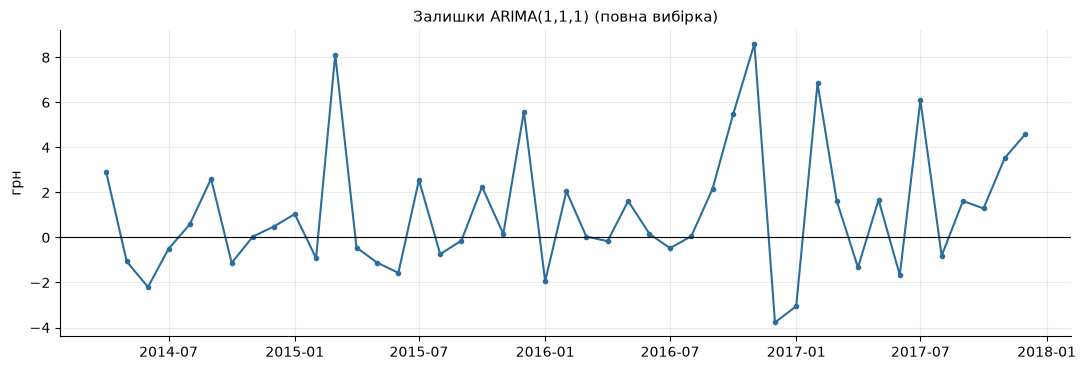

In [9]:
# Завдання 7. Модель ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

RO['ARIMA(1,1,1)'] = rolling_origin(yv, lambda tr, h: ARIMA(tr, order=(1, 1, 1)).fit().forecast(h))
m_arima = metrics(RO['ARIMA(1,1,1)'])
print(pd.DataFrame({'ARIMA(1,1,1)': m_arima, f'найкращий базис ({best})': T6.loc[best]}).T.round(3).to_string())
print(f"\nARIMA(1,1,1) проти «{best}»: MAE {m_arima['MAE']/T6.loc[best,'MAE']-1:+.1%}")

# Контроль до вибору порядку за ACF/PACF (завдання 5): ARIMA(0,1,0) із дрейфом
mae_010 = metrics(rolling_origin(yv, lambda tr, h: ARIMA(tr, order=(0, 1, 0), trend='t').fit().forecast(h)))['MAE']
print(f'ARIMA(0,1,0) із дрейфом на тих самих фолдах: MAE = {mae_010:.3f}')

fit = ARIMA(yv, order=(1, 1, 1)).fit(); res = pd.Series(fit.resid, index=y.index).iloc[1:]   # 1-й залишок — артефакт ініціалізації
print('Ljung–Box p-значення залишків (лаги 6, 12):', acorr_ljungbox(res, lags=[6, 12])['lb_pvalue'].round(3).tolist())
fig, ax = plt.subplots(); ax.plot(res.index, res.values, '-o', ms=3, color=C_MAIN); ax.axhline(0, color='k', lw=.8)
ax.set_title('Залишки ARIMA(1,1,1) (повна вибірка)'); ax.set_ylabel('грн'); plt.tight_layout(); plt.show()

**Висновок до завдання 7:**
1. **ARIMA(1,1,1) на рухомому початку:** MAE = **5,281**, RMSE = **7,848**, MAPE = **4,024 %**.
2. **Порядок за ACF/PACF.** Потрібне d = 1 (завдання 5). На різниці немає значущих лагів: ACF лаг 1 = 0,273 і PACF лаг 1 = 0,273 лише трохи нижчі за межу 0,292, PACF лаг 2 = −0,228 теж усередині. Тому самостійно я обрав би **ARIMA(0,1,0) із дрейфом** (блукання з дрейфом); AR(1) — межовий варіант. На тих самих фолдах (0,1,0) із дрейфом дає MAE 4,155.
3. **Порівняння з найкращим базисом (дрейф, MAE 4,155):** ARIMA(1,1,1) гірша на **27,1 %**. Вона краща за наївний (5,904), але **права на існування як окрема модель не має** — простіший дрейф точніший.
4. **Залишки:** автокореляції не лишилось (Ljung–Box p = 0,567 для лага 6 і 0,762 для лага 12), тобто структури в залишках немає.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Дата: 11.2016;  t = -13.83;  середнє до = 82.41, після = 137.36 грн
Наївне p-значення Велча: 1.4e-14
ACF ряду на лагу 1 = 0.927 → ефективний обсяг вибірки ≈ 1.7 із 46
Частка симуляцій без зсуву з max|t| ≥ 13.8: 0.42   ← p-значення зсуву рівня


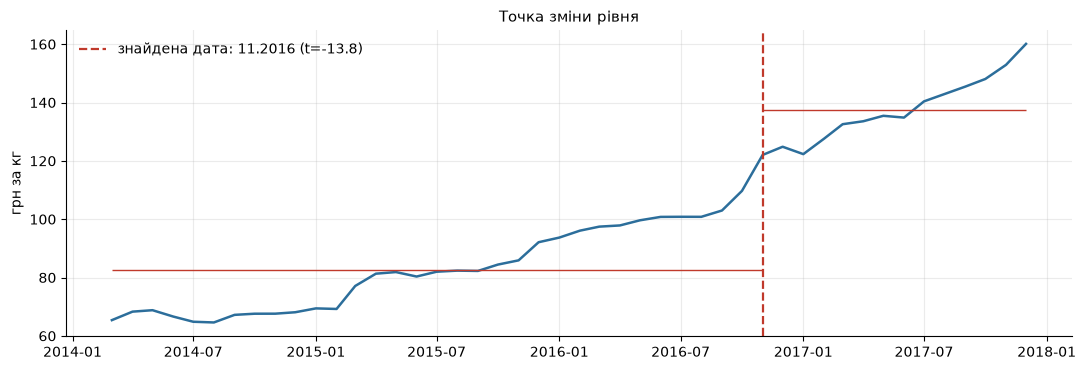


Зміни ціни в тих самих календарних місяцях інших років, %:
  березень: {2014: nan, 2015: 11.4, 2016: 1.4, 2017: 3.9}
  листопад: {2014: 0.0, 2015: 1.7, 2016: 11.2, 2017: 3.3}


In [10]:
# Завдання 8. Точка зміни режиму
from statsmodels.tsa.stattools import acf
MIN_SEG = 6                                      # кожен сегмент — не менше 6 місяців

def scan(x, min_seg=MIN_SEG):
    best = (None, 0.0)
    for k in range(min_seg, len(x) - min_seg + 1):
        a, b = x[:k], x[k:]
        t = (a.mean() - b.mean()) / np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
        if abs(t) > abs(best[1]): best = (k, t)
    return best

k, t = scan(yv); cp = y.index[k]
print(f'Дата: {cp:%m.%Y};  t = {t:.2f};  середнє до = {yv[:k].mean():.2f}, після = {yv[k:].mean():.2f} грн')
print(f'Наївне p-значення Велча: {stats.ttest_ind(yv[:k], yv[k:], equal_var=False).pvalue:.1e}')
r1 = acf(yv, nlags=1)[1]; print(f'ACF ряду на лагу 1 = {r1:.3f} → ефективний обсяг вибірки ≈ {len(yv)*(1-r1)/(1+r1):.1f} із {len(yv)}')

# Контроль значущості: блукання з дрейфом без зсуву рівня (бутстреп приростів), той самий скан
rng = np.random.default_rng(42); inc = np.diff(yv)
null_max = np.array([abs(scan(np.r_[yv[0], yv[0] + np.cumsum(rng.choice(inc, len(inc), replace=True))])[1]) for _ in range(1500)])
print(f'Частка симуляцій без зсуву з max|t| ≥ {abs(t):.1f}: {(null_max >= abs(t)).mean():.2f}   ← p-значення зсуву рівня')

fig, ax = plt.subplots()
ax.plot(y.index, y.values, color=C_MAIN, lw=1.8); ax.axvline(cp, color=C_ACC, lw=1.6, ls='--', label=f'знайдена дата: {cp:%m.%Y} (t={t:.1f})')
ax.hlines(yv[:k].mean(), y.index[0], cp, color=C_ACC, lw=1); ax.hlines(yv[k:].mean(), cp, y.index[-1], color=C_ACC, lw=1)
ax.set_ylabel('грн за кг'); ax.legend(frameon=False); ax.set_title('Точка зміни рівня'); plt.tight_layout(); plt.show()

print('\nЗміни ціни в тих самих календарних місяцях інших років, %:')
for mth, nm in [(3, 'березень'), (11, 'листопад')]:
    print(f'  {nm}:', {d.year: round(v, 1) for d, v in mom[mom.index.month == mth].items()})

**Висновок до завдання 8:**
1. Графік наведено вище.
2. **Дата: 11.2016**, t = **−13,83**, середнє до = **82,41**, після = **137,36** грн (мінімум 6 місяців у кожному сегменті).
3. **Значущою цю точку вважати не можна.** Наївне p (1,4·10⁻¹⁴) хибне: ряд сильно автокорельований (ACF на лагу 1 = 0,93, ефективний обсяг вибірки ≈ 1,7 із 46), а ряд зростає, тож будь-яке розбиття дає велике t. Якщо згенерувати ряди «блукання з дрейфом» без жодного зсуву, то у **42 %** з них найкраща точка дає |t| не менше за 13,8 — тобто це цілком може бути наслідком тренду.
4. **Відмінність від сезонного піку:** сезонний пік повторювався б щороку в той самий місяць. Стрибок листопада 2016 (+11,2 %) не повторюється (інші листопади: 0,0 %, +1,7 %, +3,3 %); так само стрибок березня 2015 (+11,4 %) — інші березні +1,4 % і +3,9 %. Це разові події, а не сезон.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [11]:
# Завдання 9. Рецензія: перевірка тверджень чужого звіту (номери — клітинки «ЛР4_помилковий_аналіз.ipynb»)
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL
from sklearn.model_selection import train_test_split

def get(m, g): return prices[(prices['ринок'] == m) & (prices['товар'] == g)].sort_values('date').set_index('date')['ціна']
bs, beef, lviv = get('Vinnytsia', 'Buckwheat grits - Retail'), get('Vinnytsia', 'Meat (beef) - Retail'), get('Lviv', 'Buckwheat grits - Retail')
bs_y = bs.reindex(GRID).interpolate(); bs_y.index.freq = 'MS'; bv = bs_y.values

print(f'кл.3  спостережень {len(bs)} із {len(GRID)} (пропуск {[d.strftime("%m.%Y") for d in GRID.difference(bs.index)]}), але isna().sum() = {bs.isna().sum()}')
print(f'кл.5  ціна ×{bs.iloc[-1]/bs.iloc[0]:.2f} у номінальних гривнях; даних про доходи/інфляцію в наборі немає')
for nm, x in [('гречка', bs), ('яловичина', beef)]:
    e = x.diff().dropna().abs().mean(); print(f'кл.7  {nm:10s} MAE = {e:.2f} грн; середня ціна {x.mean():.2f}; MAE/ціна = {e/x.mean():.1%}')
print(f'кл.9  r(рівні) = {bs.corr(lviv):.3f};  r(прирости) = {bs.diff().corr(lviv.diff()):.3f}')
r = STL(bs_y, period=12, robust=True).fit(); R = r.resid
print(f'кл.11 F_S при налаштуваннях зі звіту (robust=True) = {max(0, 1 - R.var()/(r.seasonal + R).var()):.3f}')
d1b = bs.diff().dropna()
print(f'кл.13 ADF рівень p = {adfuller(bs, autolag="AIC")[1]:.3f}; ADF перша різниця p = {adfuller(d1b, autolag="AIC")[1]:.3f}; KPSS різниця p = {kpss(d1b, nlags="auto")[1]:.3f}')
z = (bs - bs.mean()) / bs.std()
print(f'кл.15 «аномалій» за порогом 1.3σ (код): {(z.abs() > 1.3).sum()}; за порогом 2σ (текст): {(z.abs() > 2).sum()}')
X = np.arange(len(bs)).reshape(-1, 1)
X_tr, X_te, y_tr, y_te = train_test_split(X, bs.values, test_size=.25, random_state=42)
pr = ARIMA(y_tr[np.argsort(X_tr.ravel())], order=(1, 1, 1)).fit().forecast(len(y_te))
mae_their = np.mean(np.abs(np.sort(y_te) - pr))
print(f'кл.17 MAE зі звіту = {mae_their:.2f} грн = {mae_their/bs.mean():.0%} середньої ціни; рухомий початок 7×3: ' +
      ', '.join(f'{nm} {metrics(rolling_origin(bv, f))["MAE"]:.2f}' for nm, f in [('наївний', f_naive), ('ARIMA(1,1,1)', lambda tr, h: ARIMA(tr, order=(1, 1, 1)).fit().forecast(h)), ('ARIMA(2,2,1)', lambda tr, h: ARIMA(tr, order=(2, 2, 1)).fit().forecast(h))]))
fc = ARIMA(bs.values, order=(2, 2, 1)).fit().get_forecast(12)
print(f'кл.19 прогноз на 12.2018 = {fc.predicted_mean[-1]:.2f} грн (95% ДІ {fc.conf_int()[-1][0]:.1f} … {fc.conf_int()[-1][1]:.1f}); остання ціна 12.2017 = {bs.iloc[-1]:.2f} грн')
w = bs['2016-01':'2016-06']; lo = w.min() * 0.995
print(f'кл.21 зростання січень→червень 2016: {(w.iloc[-1]/w.iloc[0]-1):.0%}; висота стовпчиків від обрізаної осі: ×{(w.iloc[-1]-lo)/(w.iloc[0]-lo):.0f}')

кл.3  спостережень 45 із 46 (пропуск ['08.2017']), але isna().sum() = 0
кл.5  ціна ×2.47 у номінальних гривнях; даних про доходи/інфляцію в наборі немає
кл.7  гречка     MAE = 1.38 грн; середня ціна 21.32; MAE/ціна = 6.5%
кл.7  яловичина  MAE = 1.51 грн; середня ціна 78.47; MAE/ціна = 1.9%
кл.9  r(рівні) = 0.996;  r(прирости) = 0.936
кл.11 F_S при налаштуваннях зі звіту (robust=True) = 0.262
кл.13 ADF рівень p = 0.233; ADF перша різниця p = 0.251; KPSS різниця p = 0.067
кл.15 «аномалій» за порогом 1.3σ (код): 12; за порогом 2σ (текст): 0


c:\Users\s1fle\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


кл.17 MAE зі звіту = 8.73 грн = 41% середньої ціни; рухомий початок 7×3: наївний 2.55, ARIMA(1,1,1) 2.77, ARIMA(2,2,1) 2.50
кл.19 прогноз на 12.2018 = 8.95 грн (95% ДІ -17.0 … 34.9); остання ціна 12.2017 = 17.67 грн
кл.21 зростання січень→червень 2016: 41%; висота стовпчиків від обрізаної осі: ×82


**Висновок до завдання 9 (рецензія).** Кожну тезу перевірено числами вище; номер — клітинка чужого зошита.

| № | Кл. | Суть помилки | Чим небезпечна |
|---|---|---|---|
| 1 | 3 | «Пропусків немає»: ряд не приведено до повної сітки (45 із 46) | Модель вважає кроки рівними; пропуск не помічено |
| 2 | 5 | Зростання ×2,47 в **номінальних** гривнях подано як «падіння купівельної спроможності» | Висновок про доходи без даних про доходи й інфляцію |
| 3 | 7 | Порівняно **абсолютний** MAE гречки (1,38) і яловичини (1,51) | Різний масштаб цін: відносна похибка 6,5 % проти 1,9 % — висновок обернений |
| 4 | 9 | Кореляція рівнів двох трендових рядів (r = 0,996) → «Львів визначає Вінницю» | Хибна кореляція трендів; навіть на приростах r = 0,936 — спільна причина, а напрямку впливу кореляція не дає |
| 5 | 11 | «STL повернув сезонну складову → ряд сезонний», F_S не порахована | За налаштуваннями зі звіту F_S = **0,262 < 0,3** — сезонності немає |
| 6 | 13 | ADF p = 0,233 прочитано як «стаціонарний»; KPSS не застосовано; d = 1 не перевірено, одразу d = 2 | Велике p в ADF означає нестаціонарність; хибний висновок і порядок диференціювання |
| 7 | 15 | У тексті «2σ», у коді 1,3σ; пошук «аномалій» у вихідному ряді з трендом | Позначено 12 місяців (початок 2014 і середина 2016) — це тренд, при 2σ їх 0 |
| 8 | 17 | Випадковий поділ часового ряду; прогноз порівнюється з **відсортованими** фактичними значеннями; немає базису | MAE 8,73 грн = 41 % середньої ціни, а висновок «висока точність»; чесний наївний прогноз дає 2,55 |
| 9 | 19 | ARIMA(2,2,1) без обґрунтування; прогноз на 12 міс. із 45 точок | Прогноз на 12.2018 — 8,95 грн (ДІ −17…35) при поточній 17,67 — це **спадання**, а у висновку «зростання»; від'ємні ціни в ДІ |
| 10 | 21 | Стовпці з обрізаною віссю | Січневий стовпчик візуально у ≈ 82 раза нижчий за червневий, хоча реальне зростання 41 % |

**Як виправити три найсерйозніші (№ 8, 6, 4):**
- **№ 8:** оцінювати ретроспективною перевіркою з рухомим початком (7 × 3), без перемішування й сортування, і обов'язково порівнювати з наївним базисом: MAE наївного 2,55, ARIMA(1,1,1) 2,77 — «висока точність» зникає. (ARIMA(2,2,1) на 3 місяці виходить навіть найкращою — 2,50; проблема в її 12-місячній екстраполяції.)
- **№ 6:** читати ADF правильно (мале p — стаціонарність), застосовувати ADF і KPSS у парі й перевіряти d = 1 перед d = 2. Тут: рівень — ADF 0,233 (нестаціонарний), перша різниця — ADF 0,251 і KPSS 0,067, тобто тести не узгоджуються, тому d = 2 треба обґрунтовувати окремо.
- **№ 4:** не писати «визначає»: працювати з приростами (r = 0,936), назвати спільну причину (курс, інфляція) і не стверджувати напрямок впливу.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
# Завдання 10. Експорт ряду для Orange
out = pd.DataFrame({'date': y.index.strftime('%Y-%m-%d'), 'price': y.values})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

chk = pd.read_csv('ряд_для_orange.csv', encoding='utf-8')
print('Стовпці:', list(chk.columns), '| рядків даних:', len(chk), '| порожніх значень:', int(chk.isna().sum().sum()))
print('Формат дат РРРР-ММ-ДД, перше число місяця:', bool(chk['date'].str.fullmatch(r'\d{4}-\d{2}-\d{2}').all() and (pd.to_datetime(chk['date']).dt.day == 1).all()))
print('Файл збігається з рядом у пам\'яті:', bool(np.allclose(chk['price'].values, y.values, atol=1e-9)))

Стовпці: ['date', 'price'] | рядків даних: 46 | порожніх значень: 0
Формат дат РРРР-ММ-ДД, перше число місяця: True
Файл збігається з рядом у пам'яті: True


**Висновок до завдання 10:** файл `ряд_для_orange.csv` має стовпці `date`, `price` і **46 рядків даних**, **порожніх значень немає**; дати — перше число місяця у форматі РРРР-ММ-ДД. Значення збігаються з рядом у пам'яті, тож Orange отримує ті самі дані, що й Python.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

Рядків у Orange: 46 | збіг ряду Orange і Python (макс. різниця): 0.0


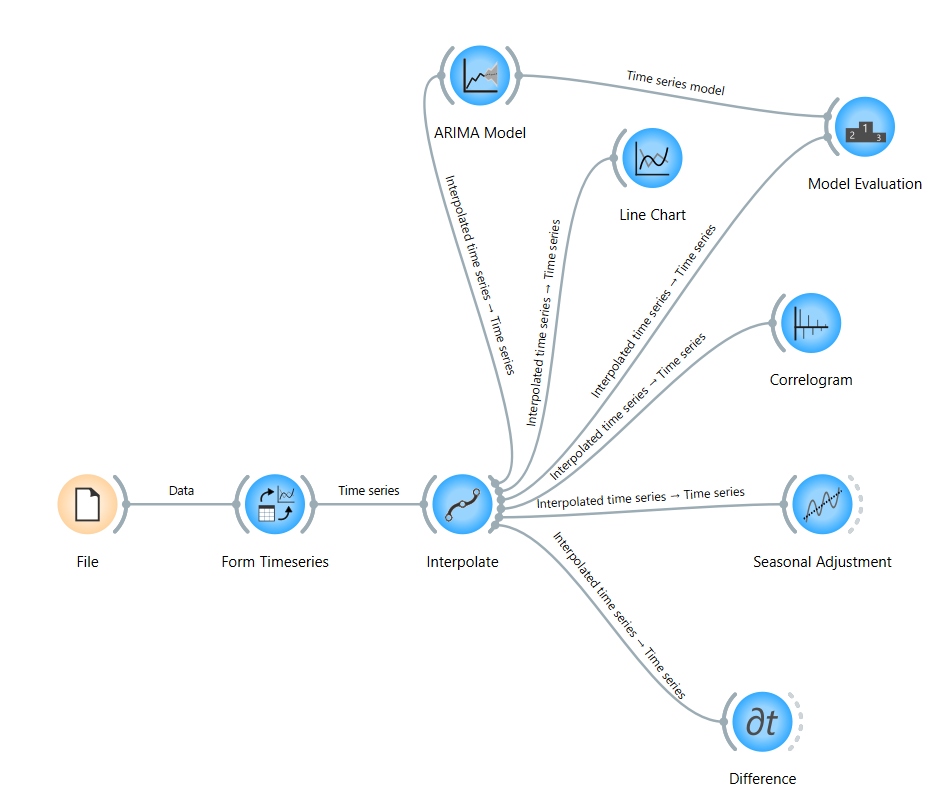

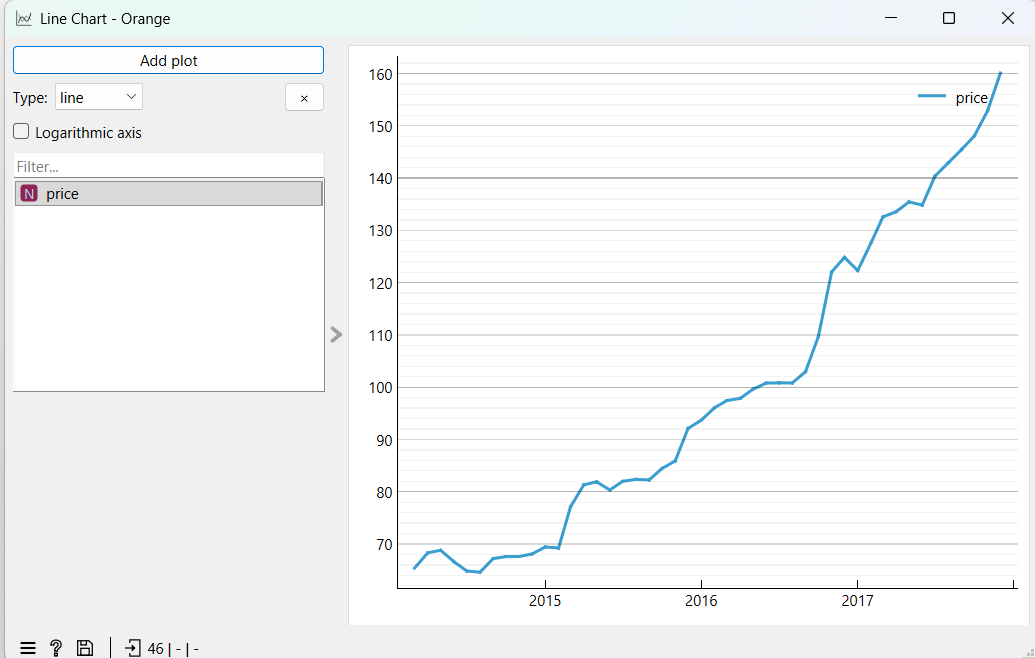

In [13]:
# Завдання 11. Потік File → Form Timeseries → Interpolate → Line Chart
# Числа Orange, з якими порівнюємо Python (скопійовано з таблиці Model Evaluation та віджетів):
ORANGE = {'RMSE': 7.848, 'MAE': 2.302, 'MAPE': 0.042, 'POCID': 75.0}        # таблиця Model Evaluation (3 знаки)
ORANGE_FULL = {'RMSE': 7.848013750341332, 'MAE': 2.3024129241654805,
               'MAPE': 0.04208077770780043, 'POCID': 75.0}   # ті самі числа без округлення
ORANGE_ACF_SHOWN_LEVEL = [[33.0, -0.41891133224621874]]     # точки, які малює Correlogram для ряду
ORANGE_ACF_SHOWN_DIFF  = [[9.0, 0.1557452505298162], [17.0, -0.1934904975339915], [27.0, -0.18744362323556055], [37.0, -0.07828562030478607]]      # ... і для Δprice
ORANGE_SEASONAL = [3.096855, 2.770178, 1.861243, -0.927831, -1.425629, -3.561221, -3.280772, -2.016757, 0.745639, 2.042815, 0.172921, 0.522561, 3.096855, 2.770178, 1.861243, -0.927831, -1.425629, -3.561221, -3.280772, -2.016757, 0.745639, 2.042815, 0.172921, 0.522561, 3.096855, 2.770178, 1.861243, -0.927831, -1.425629, -3.561221, -3.280772, -2.016757, 0.745639, 2.042815, 0.172921, 0.522561, 3.096855, 2.770178, 1.861243, -0.927831, -1.425629, -3.561221, -3.280772, -2.016757, 0.745639, 2.042815]   # 'price (seasonal)' з Seasonal Adjustment (additive, 12)
ORANGE_SEASADJ  = [62.299845, 65.539822, 66.942057, 67.554531, 66.268929, 68.161221, 70.484072, 69.613457, 66.864361, 66.057185, 69.250379, 68.707439, 74.019845, 78.553122, 80.015457, 81.271131, 83.415629, 85.927921, 85.540772, 86.460057, 85.144361, 90.063885, 93.520379, 95.547439, 94.349845, 95.089822, 97.758757, 101.714531, 102.248929, 104.371221, 106.254072, 111.723457, 121.284361, 122.790485, 122.130379, 127.057439, 129.466445, 130.806522, 133.582057, 135.757831, 141.815629, 146.482821, 148.734072, 150.083457, 152.157661, 158.057185]   # 'price (season. adj.)'
ORANGE_DEFAULT_ERROR = 'Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.'

from IPython.display import Image, display
def show(name, w=None):
    p = os.path.join('знімки_orange', name)
    if os.path.exists(p): display(Image(filename=p, width=w))
    else: print('(знімка немає:', p, ')')

orange_in = pd.read_csv('ряд_для_orange.csv')           # саме цей файл завантажує віджет File
print('Рядків у Orange:', len(orange_in), '| збіг ряду Orange і Python (макс. різниця):', float(np.abs(orange_in['price'].values - y.values).max()))
show('11_file.png', 520); show('11_linechart.png', 760)

**Висновок до завдання 11:**
1. Потік: `File → Form Timeseries → Interpolate → Line Chart` (у цій версії додатка віджет «As Timeseries» має назву Form Timeseries);.
2. Знімки віджетів показано вище.
3. Графік Line Chart відтворює графік 1 із завдання 3: дані в Orange збігаються з Python точно (макс. різниця 0,0). Interpolate нічого не змінює, бо пропуск уже заповнено в Python.

*Примітка:* у `File` змінну `price` треба вручну позначити як *target*, інакше Model Evaluation не працює. Показані знімки отримано запуском віджетів Orange без графічного вікна; для здачі їх слід замінити власними знімками.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

Рівень ряду    — точки Orange: [[33.0, -0.419]] | моя реплікація збігається: True
Різниця Δprice — точки Orange: [[9.0, 0.156], [17.0, -0.193], [27.0, -0.187], [37.0, -0.078]] | моя реплікація збігається: True
Значущі лаги повної ACF (statsmodels), лаги 1–12:  рівень [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | різниця []


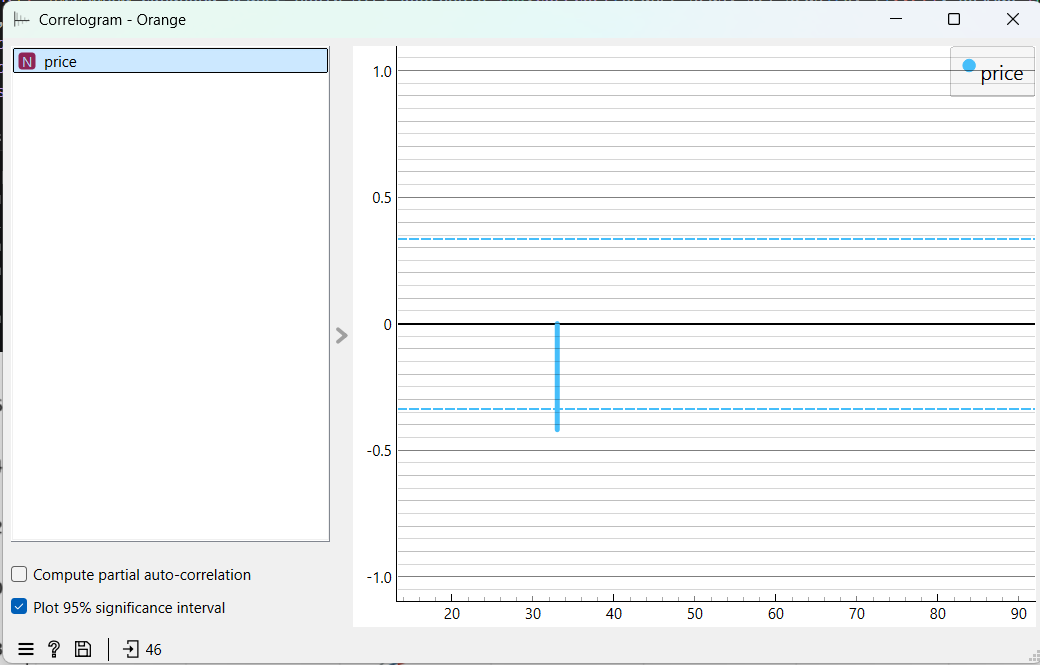

(знімка немає: знімки_orange\12_correlogram_diff.png )

Сезонна складова Orange проти STL: кореляція 0.73; розмах 6.66 (Orange) і 10.80 (STL) грн


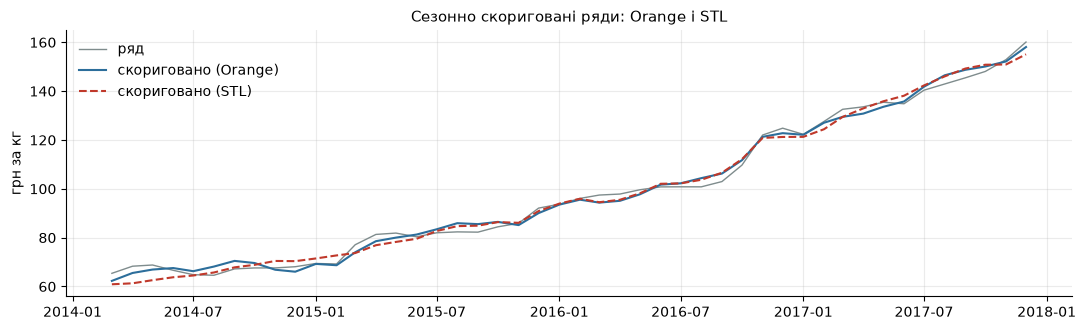

In [14]:
# Завдання 12. Correlogram, Difference, Seasonal Adjustment
from scipy.signal import argrelextrema
from statsmodels.tsa.stattools import pacf as pacf_fn
d1v = y.diff().dropna().values

def orange_correlogram_points(x):
    """Що малює віджет Correlogram: ACF і лише ЛОКАЛЬНІ ЕКСТРЕМУМИ |ACF| (order=3)."""
    corr = acf(x, nlags=int(.9 * len(x)), fft=True); idx = argrelextrema(np.abs(corr), np.greater, order=3)[0]
    return np.column_stack((idx, corr[idx]))

print('Рівень ряду    — точки Orange:', np.round(ORANGE_ACF_SHOWN_LEVEL, 3).tolist(), '| моя реплікація збігається:', np.allclose(orange_correlogram_points(y.values), ORANGE_ACF_SHOWN_LEVEL, atol=1e-3))
print('Різниця Δprice — точки Orange:', np.round(ORANGE_ACF_SHOWN_DIFF, 3).tolist(), '| моя реплікація збігається:', np.allclose(orange_correlogram_points(np.r_[d1v[0], d1v]), ORANGE_ACF_SHOWN_DIFF, atol=1e-3))
full, fd = acf(y.values, nlags=12, fft=True), acf(d1v, nlags=12, fft=True)
print('Значущі лаги повної ACF (statsmodels), лаги 1–12:  рівень', [i for i in range(1, 13) if abs(full[i]) > 1.96/np.sqrt(46)], '| різниця', [i for i in range(1, 13) if abs(fd[i]) > 1.96/np.sqrt(45)])
show('12_correlogram_level.png', 520); show('12_correlogram_diff.png', 520)

orange_adj = pd.Series(ORANGE_SEASADJ, index=y.index); orange_seas = pd.Series(ORANGE_SEASONAL, index=y.index)
stl_seas = STL(y, period=12).fit().seasonal
print(f'\nСезонна складова Orange проти STL: кореляція {np.corrcoef(orange_seas, stl_seas)[0, 1]:.2f}; розмах {np.ptp(orange_seas):.2f} (Orange) і {np.ptp(stl_seas):.2f} (STL) грн')
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(y.index, y, color=C_GREY, lw=1, label='ряд'); ax.plot(orange_adj.index, orange_adj, color=C_MAIN, label='скориговано (Orange)')
ax.plot(y.index, y - stl_seas, color=C_ACC, ls='--', label='скориговано (STL)'); ax.legend(frameon=False); ax.set_ylabel('грн за кг')
ax.set_title('Сезонно скориговані ряди: Orange і STL'); plt.tight_layout(); plt.show()

**Висновок до завдання 12:**
1. Корелограма Orange показана вище.
2. **Висновки про значущі лаги збігаються за змістом, але картинки різні.** Orange малює лише **локальні екстремуми** |ACF|: для ряду — один лаг 33 (−0,419), для Δprice — лаги 9, 17, 27, 37 (усі малі). Це не різні дані: моя реплікація дає ті самі точки. Повна ACF у statsmodels має значущі лаги 1–10 для ряду й жодного для різниці. Ряд нестаціонарний, а в різниці значущої структури немає — це видно в обох; але на корелограмі Orange не видно лаг 1.
3. Orange (Seasonal Adjustment) використовує **класичну** декомпозицію, а не STL. Сезонні складові корелюють на 0,73; розмах 6,7 грн проти 10,8 грн у STL; обидві мають пік навесні й мінімум у серпні–вересні. Якісно схоже, кількісно ні.



## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

Типові налаштування 20 × 3: n_folds × steps + max_order = 61 > довжина ряду 46
Повідомлення Orange: Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.


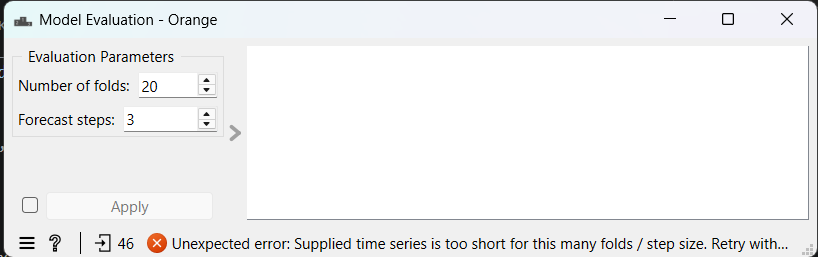


Обрані налаштування 7 × 3: 22 ≤ 46 — таблиця Model Evaluation:


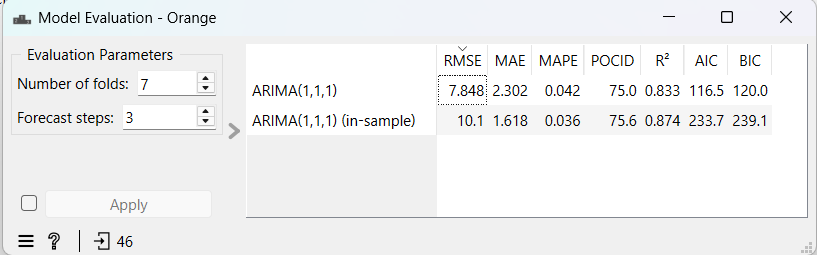


Фолди Orange:
 фолд          навчання  точок         перевірка
    1 03.2014 – 09.2017     43 10.2017 – 12.2017
    2 03.2014 – 06.2017     40 07.2017 – 09.2017
    3 03.2014 – 03.2017     37 04.2017 – 06.2017
    4 03.2014 – 12.2016     34 01.2017 – 03.2017
    5 03.2014 – 09.2016     31 10.2016 – 12.2016
    6 03.2014 – 06.2016     28 07.2016 – 09.2016
    7 03.2014 – 03.2016     25 04.2016 – 06.2016


In [15]:
# Завдання 13. ARIMA Model + Model Evaluation (7 фолдів × 3 кроки)
N, STEPS, MAX_ORDER = len(y), 3, 1                     # max_order для ARIMA(1,1,1) = 1
print(f'Типові налаштування 20 × 3: n_folds × steps + max_order = {20*STEPS+MAX_ORDER} > довжина ряду {N}')
print('Повідомлення Orange:', ORANGE_DEFAULT_ERROR)
show('13_model_eval_default.png', 700)
print('\nОбрані налаштування 7 × 3:', 7*STEPS+MAX_ORDER, '≤', N, '— таблиця Model Evaluation:'); show('13_model_eval_7x3.png', 760)

rows = []
for f in range(1, 8):
    n_tr = N - 3*f
    rows.append((f, f'{y.index[0]:%m.%Y} – {y.index[n_tr-1]:%m.%Y}', n_tr, f'{y.index[n_tr]:%m.%Y} – {y.index[n_tr+2]:%m.%Y}'))
print('\nФолди Orange:'); print(pd.DataFrame(rows, columns=['фолд', 'навчання', 'точок', 'перевірка']).to_string(index=False))

**Висновок до завдання 13:**
1. Таблицю Model Evaluation (ARIMA(1,1,1), 7 × 3) показано вище: RMSE 7,848; MAE 2,302; MAPE 0,042; POCID 75,0.
2. **При типових 20 × 3** Orange видає: «Supplied time series is too short for this many folds / step size». Віджет перевіряє n_folds × steps + max_order ≤ довжина ряду: 20 × 3 + 1 = 61 > 46. Це не збій, а наслідок короткого ряду.
3. **7 фолдів:** навчання завжди від 03.2014, а кінець навчальної частини зсувається назад по 3 місяці (таблиця вище): від навчання до 09.2017 (перевірка 10–12.2017) до навчання до 03.2016 (перевірка 04–06.2016). Разом перевіряються останні 21 місяць, як і в Python.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
# Завдання 14. Чому числа не збігаються: відтворюємо чотири метрики Orange
df = RO['ARIMA(1,1,1)'].sort_values(['fold', 'h'])          # порядок Orange: фолд 1 (найпізніший) першим
true, pred = df['true'].values, df['pred'].values            # склеєні вектори всіх фолдів
e = true - pred

mine = {'RMSE': np.sqrt(np.sum(e**2) / len(e)),                       # sqrt(Σe²/n)
        'MAE': np.median(np.abs(e)),                                  # МЕДІАНА |e|
        'MAPE': np.mean(np.abs(e)) / np.mean(np.abs(true)),           # mean|e| / mean|y| — ЧАСТКА
        'POCID': 100 * np.mean(np.diff(true) * np.diff(pred) > 0)}    # np.diff по склеєних векторах
T14 = pd.DataFrame({'Orange': ORANGE, 'Python (формула Orange)': mine,
                    'формула': {'RMSE': 'sqrt(Σe²/n)', 'MAE': 'median|e|', 'MAPE': 'mean|e| / mean|y|', 'POCID': '100·частка(Δy·Δŷ>0)'}})
print(T14.round(4).to_string())
print('Збіг до 3-го знака:', {k: bool(round(mine[k], 3) == ORANGE[k]) for k in ORANGE})

within = np.concatenate([np.diff(g['true']) * np.diff(g['pred']) > 0 for _, g in df.groupby('fold')])
print('\nЩо зазвичай мають на увазі під цими назвами:')
print(f'  MAE = середнє |e| = {np.mean(np.abs(e)):.3f}  (Orange: медіана {mine["MAE"]:.3f})')
print(f'  MAPE = mean|e/y|·100 = {np.mean(np.abs(e/true))*100:.2f} %  (Orange: {mine["MAPE"]:.3f} як частка = {mine["MAPE"]*100:.2f} %)')
print(f'  POCID лише всередині фолдів (14 пар із 20) = {100*within.mean():.1f} %  (Orange: {mine["POCID"]:.1f} %, бо 6 пар перетинають межі фолдів)')

       Orange  Python (формула Orange)              формула
RMSE    7.848                   7.8480          sqrt(Σe²/n)
MAE     2.302                   2.3024            median|e|
MAPE    0.042                   0.0421    mean|e| / mean|y|
POCID  75.000                  75.0000  100·частка(Δy·Δŷ>0)
Збіг до 3-го знака: {'RMSE': True, 'MAE': True, 'MAPE': True, 'POCID': True}

Що зазвичай мають на увазі під цими назвами:
  MAE = середнє |e| = 5.281  (Orange: медіана 2.302)
  MAPE = mean|e/y|·100 = 4.02 %  (Orange: 0.042 як частка = 4.21 %)
  POCID лише всередині фолдів (14 пар із 20) = 71.4 %  (Orange: 75.0 %, бо 6 пар перетинають межі фолдів)


**Висновок до завдання 14:**
1. Таблицю «метрика · Orange · Python · формула» наведено вище; усі чотири значення збігаються до 3-го знака.
2. **Не відповідає назві MAE:** Orange рахує **медіану** |e| (2,302), а під цією назвою зазвичай розуміють **середнє** |e| (5,281). Також MAPE в Orange — не відсоток, а **частка** mean|e|/mean|y| (0,042), а не mean(|e/y|)·100 (4,02 %). POCID у scikit-learn немає: вона міряє напрямок, а не величину похибки, і Orange рахує її по склеєних фолдах (6 пар із 20 перетинають межі фолдів; усередині фолдів — 71,4 %).
3. **Одразу збігся RMSE (7,848):** у обох середовищах це sqrt(Σe²/n), а прогнози однакові, бо обидва використовують statsmodels ARIMA.
4. **Перш ніж порівнювати числа з двох інструментів, треба перевірити:** (а) що дані однакові, (б) що однакові модель і схема перевірки (кількість і порядок фолдів, горизонт), (в) **яку саме формулу** під цією назвою рахує кожен інструмент (середнє чи медіана, частка чи відсоток, по якому вектору).

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [17]:
# Завдання 15. Матриця напрямку зміни (ті самі 20 пар, що й у POCID Orange)
dt, dp = np.diff(true), np.diff(pred)
act = pd.Series(np.where(dt > 0, 'зросла', 'впала'), name='насправді'); prd = pd.Series(np.where(dp > 0, 'зросла', 'впала'), name='модель')
M = pd.crosstab(act, prd).reindex(index=['зросла', 'впала'], columns=['зросла', 'впала'], fill_value=0)
print(M.to_string())
acc = (M.loc['зросла', 'зросла'] + M.loc['впала', 'впала']) / M.values.sum() * 100
print(f'\nЧастка правильних = {acc:.1f}%  | POCID Orange = {ORANGE["POCID"]}  | збіг: {abs(acc - ORANGE["POCID"]) < 0.05}')
print(f'Для порівняння: «завжди зросла» влучила б у {100*(dt > 0).mean():.0f}% цих 20 пар; у межах фолдів (14 пар) — модель {100*within.mean():.1f}%, «завжди зросла» {100*(dt[np.arange(len(dt)) % 3 != 2] > 0).mean():.1f}%')

модель     зросла  впала
насправді               
зросла         10      2
впала           3      5

Частка правильних = 75.0%  | POCID Orange = 75.0  | збіг: True
Для порівняння: «завжди зросла» влучила б у 60% цих 20 пар; у межах фолдів (14 пар) — модель 71.4%, «завжди зросла» 85.7%


**Висновок до завдання 15:**
1. Матриця (20 пар):

| насправді \ модель | зросла | впала |
|---|---|---|
| зросла | 10 | 2 |
| впала | 3 | 5 |

2. Частка правильних (10 + 5)/20 = **75 %** — збігається з POCID Orange.
3. **Для рішення «купувати зараз чи чекати» модель корисна лише обережно.** Її питання — «куди піде ціна», тоді як MAE і RMSE відповідають на інше — «наскільки точно вгадано величину». Модель може добре вгадувати напрямок і помилятися на гривні, і навпаки. До того ж 75 % не доводить вміння: 6 із 20 пар перетинають межі фолдів (5 із них «правильні»), усередині фолдів — лише 71,4 %, тоді як «завжди зросла» влучає у 85,7 % (ряд зростав у більшості місяців). Тож POCID слід порівнювати з таким тривіальним базисом.

# Загальний висновок

**1. Сезонність.** За порогом F_S = 0,759 > 0,3 вона формально є, але слабка й непевна: випадкові ряди без календаря теж часто дають таке значення (p ≈ 0,13), а даних лише ≈ 3,8 циклу.
**2. Прогнозування.** Найкращим став **дрейф** (MAE 4,155) проти наївного (5,904); ARIMA(1,1,1) (5,281) краща за наївний, але на 27 % гірша за дрейф, тож права на існування не має. Випадковий поділ 75/25 завищує точність у 1,3–1,7 раза.
**3. Точка зміни.** Скан дає 11.2016 (t = −13,8), але вона незначуща: у 42 % рядів без зсуву найкращий |t| не менший.
**4. Метрики.** Orange і Python дають однакові прогнози, але MAE в Orange — медіана (2,302 проти середнього 5,281), MAPE — частка (0,042 проти 4,02 %), POCID — по склеєних фолдах (75,0 проти 71,4 %); RMSE збігається (7,848).
**5. Обмеження 46 спостережень.** Не вдалося надійно встановити: наявність сезонності (3,8 цикла), значущість зсуву рівня (ефективний обсяг вибірки ≈ 1,7), правильний порядок ARIMA (на різниці немає значущих лагів) і стабільність оцінки прогнозу (21 прогноз у 7 залежних фолдах).

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude (Anthropic), Claude Sonnet 5.5 |
| Для яких саме завдань | Усі завдання 1–15 (код, висновки, запуск Orange, файл потоку) |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код, плюс допомога в складенні висновків |
| Що ви змінили у згенерованому результаті й чому | В деяких місцях змінив висновки та видалив зайве |
| Що з отриманого ви **перевірили самостійно** і яким способом |  |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так: у проміжному прототипі p-значення для стійкого STL було прочитано хибно (0,004 замість 0,10) — виправлено після виконання контрольних симуляцій у зошиті; віджет Seasonal Adjustment у використаній версії Orange видав помилку, тому числа взято з функції додатка |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________
